# 01: First look at ScholarCatalyst

Goal: learn the schema before writing loaders. Checks subset sizes against the dataset card, how labels are stored, whether every labeled ID resolves in the corpus, and anything odd about dates and categories that would break the date filter or the cross-field split.

Data comes from `scripts/download_data.py` (not committed, CC BY-NC 4.0).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

D = '../data/'
corpus = pd.read_parquet(D + 'corpus.parquet')
queries = pd.read_parquet(D + 'queries.parquet')
core = pd.read_parquet(D + 'core_query.parquet')
sub = pd.read_parquet(D + 'subfield_query.parquet')
{k: len(v) for k, v in dict(corpus=corpus, queries=queries, core=core, sub=sub).items()}

{'corpus': 190896, 'queries': 894, 'core': 207, 'sub': 687}

## Schema

In [2]:
for name, df in dict(corpus=corpus, queries=queries, core=core, sub=sub).items():
    print(name, dict(df.dtypes.astype(str)))

corpus {'id': 'str', 'title': 'str', 'text': 'str', 'primary_category': 'str', 'categories': 'object', 'published': 'str'}
queries {'id': 'str', 'paper_id': 'str', 'question': 'str', 'type': 'str', 'paper_published': 'str', 'paper_domain': 'str'}
core {'query_id': 'str', 'positive_docs': 'object', 'hard_negatives': 'object'}
sub {'query_id': 'str', 'positive_docs': 'object', 'hard_negatives': 'object', 'author_rationale': 'str'}


Label format differs between the two query types:

- **core**: `positive_docs` is a list of `{id, author_rationale}`, one rationale per credited paper.
- **subfield**: `positive_docs` is a plain list of IDs, with one `author_rationale` for the whole query.

So RQ1 type labeling has two granularities: per paper for core, per query for subfield.

In [3]:
core['pos_ids'] = core.positive_docs.map(lambda xs: [x['id'] for x in xs])
sub['pos_ids'] = sub.positive_docs.map(list)
labels = pd.concat([core[['query_id', 'pos_ids', 'hard_negatives']],
                    sub[['query_id', 'pos_ids', 'hard_negatives']]])
labels['n_pos'] = labels.pos_ids.map(len)
labels['n_neg'] = labels.hard_negatives.map(len)
labels['type'] = labels.query_id.str.contains('core').map({True: 'core', False: 'subfield'})
labels.groupby('type')[['n_pos', 'n_neg']].agg(['mean', 'min', 'max']).round(2)

n_pos          n_neg        
          mean min max   mean min max
type                                 
core      3.19   1  10  10.01   4  13
subfield  6.09   1  15   6.88   0  13

Compare with the proposal's table: core 3.2 credited / 10.0 rejected, subfield 6.1 / 6.9.

In [4]:
n_rationales = core.positive_docs.map(len).sum() + len(sub)
print('core per-paper rationales:', core.positive_docs.map(len).sum())
print('subfield per-query rationales:', len(sub))
print('total to label for RQ1:', n_rationales)

core per-paper rationales: 661
subfield per-query rationales: 687
total to label for RQ1: 1348


## Projects

Queries group into projects by `paper_id`. Folds must be built over these.

In [5]:
per_project = queries.groupby('paper_id').type.value_counts().unstack(fill_value=0)
print(per_project.sum(axis=1).describe())
print('every project has exactly one core query:', (per_project['core_query'] == 1).all())

count    207.000000
mean       4.318841
std        0.664482
min        2.000000
25%        4.000000
50%        4.000000
75%        5.000000
max        6.000000
dtype: float64
every project has exactly one core query: True


Why folds have to be project-level: how often do a project's subfield positives overlap its core positives?

In [6]:
q2p = queries.set_index('id').paper_id
labels['paper_id'] = labels.query_id.map(q2p)
core_pos = labels[labels.type == 'core'].set_index('paper_id').pos_ids.map(set)
s = labels[labels.type == 'subfield']
shared = [bool(set(p) & core_pos[pid]) for pid, p in zip(s.paper_id, s.pos_ids)]
print(f'subfield queries sharing a positive with their core query: {sum(shared)}/{len(shared)}')

subfield queries sharing a positive with their core query: 378/687


## Do all labeled IDs resolve in the corpus?

In [7]:
ids = set(corpus.id)
all_pos = {i for xs in labels.pos_ids for i in xs}
all_neg = {i for xs in labels.hard_negatives for i in xs}
print('missing positives:', len(all_pos - ids), '/', len(all_pos))
print('missing negatives:', len(all_neg - ids), '/', len(all_neg))
print('IDs that are a positive for one query and a negative for another:', len(all_pos & all_neg))

missing positives: 0 / 3854
missing negatives: 0 / 5319
IDs that are a positive for one query and a negative for another: 905


## Dates

The date filter keeps only candidates published no later than the source paper. `published` is stored as a string, so parse it first.

In [8]:
shape = corpus.published.str.replace(r'\d', '9', regex=True)
pd.DataFrame({'n': shape.value_counts(),
              'example_id': corpus.groupby(shape).id.first()})

,n,example_id
published,,
9999,21,s2_076fac0f173df6c85ef03ea7f708a00eb2118211
9999-99,4,s2_baa747bd76a941a2909ec9c424597e72be967ed6
9999-99-99,10144,arxiv_2412.18076
9999-99-99 99:99:99,180727,arxiv_2001.00116


Four formats. Full timestamps and plain dates are fine. Year-only (`2023`) and year-month (`2008-01`) parse to the first day of the period, so the date filter treats them as earlier than they may be: a year-only paper from late 2025 would pass the filter for a July 2025 source paper. These come from Semantic Scholar (`s2_` IDs), not arXiv.

In [9]:
corpus['pub'] = pd.to_datetime(corpus.published, format='ISO8601')
queries['src_pub'] = pd.to_datetime(queries.paper_published, format='ISO8601')
print(corpus.pub.describe())
print(corpus.pub.dt.year.value_counts().sort_index())

count                        190896
mean     2022-09-14 21:43:20.201157
min             1899-12-30 00:00:00
25%             2021-06-29 00:00:00
50%             2022-11-18 00:00:00
75%             2024-01-18 00:00:00
max             2026-07-22 00:00:00
Name: pub, dtype: object
pub
1899        1
1931        1
1933        1
1936        1
1950        1
        ...  
2022    33956
2023    42091
2024    47029
2025     2386
2026      187
Name: count, Length: 71, dtype: int64


In [10]:
weird = corpus[corpus.pub.dt.year < 1990]
print(len(weird), 'papers with a pre-1990 date')
weird[['id', 'title', 'published', 'primary_category']].head()

64 papers with a pre-1990 date


,id,title,published,primary_category
186304,oa_W119405489,Rediscovering physics with BACON.3,1979-08-20,Generality
186305,oa_W127874511,BAC0N.5: the discovery of conservation laws,1981-08-24,Heuristics
186308,oa_W149130585,THE PRONOUNS OF POWER AND SOLIDARITY,1968-12-31,Solidarity
186313,oa_W1548517564,Mean Reversion in Stock Prices? A Reappraisal ...,1988-12-01,Mean reversion
186318,oa_W1599972278,Scientific Discovery: Computational Exploratio...,1988-01-01,Computer science


Mostly genuine old papers (BACON.3 is 1979), pulled in from OpenAlex (`oa_` IDs). The one exception is `1899-12-30`, which is day zero in spreadsheet date systems, so it is a missing date, not a real one. Their `primary_category` is an OpenAlex concept (`Generality`, `Solidarity`), not an arXiv code.

In [11]:
import re
print(weird.id.str.extract(r'^(\w+?)_')[0].value_counts())

0
oa    56
s2     8
Name: count, dtype: int64


In [12]:
pos_pub = labels.explode('pos_ids').merge(corpus[['id', 'pub']], left_on='pos_ids', right_on='id')
pos_pub['src_pub'] = pos_pub.query_id.map(queries.set_index('id').src_pub)
late = pos_pub[pos_pub.pub > pos_pub.src_pub]
print('credited papers published AFTER their source paper:', len(late), '/', len(pos_pub))
late[['query_id', 'pos_ids', 'pub', 'src_pub']].head()

credited papers published AFTER their source paper: 27 / 4845


,query_id,pos_ids,pub,src_pub
21,q_2505.12565_core_query_0,s2_b44fb6bbe799780734c8c0362951d8f2a1210cf3,2025-06-18,2025-05-18
53,q_2511.05924_core_query_0,arxiv_2603.25832,2026-03-26,2025-11-08
187,q_2505.18943_core_query_0,arxiv_2509.23441,2025-09-27,2025-05-25
226,q_2502.02770_core_query_0,arxiv_2502.12216,2025-02-17,2025-02-04
476,q_2602.05372_core_query_0,arxiv_2602.07351,2026-02-07,2026-02-05


**Important:** a strict `pub <= src_pub` filter would delete these credited papers from their own queries, making them impossible to retrieve. Likely causes: the corpus date is the latest arXiv version rather than v1, or authors credited a paper that appeared while their work was in progress. **Judgment call for the date filter:** exempt labeled papers, allow a grace window, or drop them and report it. Check how the ScholarCatalyst code handles this before deciding.

Source papers by date. The Qwen3 embedding/reranker models were released in June 2025, so this decides how big the pre/post-release check (Section 7) can be.

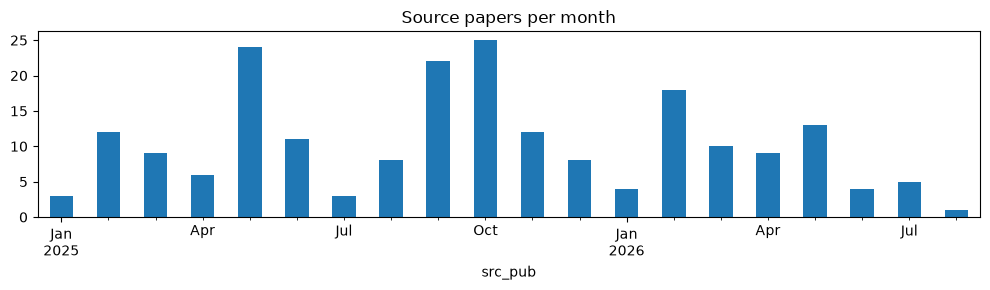

In [13]:
queries.drop_duplicates('paper_id').src_pub.dt.to_period('M').value_counts().sort_index().plot.bar(figsize=(10, 3), title='Source papers per month')
plt.tight_layout()

## Categories

Cross-field = credited paper's arXiv category differs from the source paper's.

In [14]:
corpus.primary_category.value_counts().head(15)

primary_category
cs.CV               64919
cs.LG               57151
cs.CL               33255
cs.RO               18922
cs.AI               10933
eess.IV               728
eess.SY               565
Computer Science      565
cs.HC                 347
stat.ML               244
                      226
cs.CR                 186
cs.MA                 172
math.OC               169
cs.SE                 161
Name: count, dtype: int64

In [15]:
non_arxiv = corpus[~corpus.primary_category.str.match(r'^[a-z\-]+(\.[A-Za-z\-]+)?$')]
non_arxiv.primary_category.value_counts().head(10)

primary_category
Computer Science           565
                           226
Computer science           140
Medicine                   116
Mathematics                 33
Reinforcement learning      21
Psychology                  19
Biology                     11
Benchmark (surveying)        8
Artificial intelligence      7
Name: count, dtype: int64

Rough cross-field rate on core positives, using primary categories only. The paper reports 49.5% (probably with a different definition, so a gap is not alarming yet).

In [16]:
cat = corpus.set_index('id').primary_category
cp = labels[labels.type == 'core'].explode('pos_ids')
cp['src_cat'] = cp.query_id.map(queries.set_index('id').paper_domain)
cp['pos_cat'] = cp.pos_ids.map(cat)
print(f"cross-field (primary category differs): {(cp.src_cat != cp.pos_cat).mean():.1%}")

cross-field (primary category differs): 51.6%


## Notes for later

- Two rationale granularities (per paper vs per query) for RQ1 labeling.
- 27 of 4,845 credited (query, paper) pairs postdate their source paper; the date filter must not silently drop them.
- One missing date shows up as `1899-12-30`.
- 905 papers are credited for one query and rejected for another, so 'rejected' is query-specific, never a global label.
- 378 of 687 subfield queries share a credited paper with their own core query: confirms folds must be per project.
- Dates come in four formats; year-only and year-month dates are coarse and bias the filter toward keeping papers.
- Some `primary_category` values are not arXiv codes (Semantic Scholar fields, OpenAlex concepts, blanks); the cross-field definition needs a mapping. Naive primary-category mismatch gives 51.6% vs the paper's 49.5%.
- Project = `paper_id`; folds go over these.